In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

In [2]:
case_test = pd.read_csv('data/csv/calc_case_description_test_set.csv')
case_train = pd.read_csv('data/csv/calc_case_description_train_set.csv')
mass_test = pd.read_csv('data/csv/mass_case_description_test_set.csv')
mass_train = pd.read_csv('data/csv/mass_case_description_train_set.csv')

In [3]:
case_test.head()

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00038,2,LEFT,CC,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00038,2,LEFT,MLO,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00038,2,RIGHT,CC,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....
3,P_00038,2,RIGHT,CC,2,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....
4,P_00038,2,RIGHT,MLO,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...


In [4]:
case_train.head()

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...


In [5]:
mass_test.head()

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,2,Mass-Test_P_00032_RIGHT_CC/1.3.6.1.4.1.9590.10...,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....


In [6]:
mass_train.head()

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


## Working only with 'case' for this template. Duplicate for 'mass'

In [7]:
# list all columns
print(case_train.columns)

# print unique values of pathology 
print(case_train['pathology'].unique())

Index(['patient_id', 'breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'pathology', 'subtlety', 'image file path',
       'cropped image file path', 'ROI mask file path'],
      dtype='object')
['MALIGNANT' 'BENIGN' 'BENIGN_WITHOUT_CALLBACK']


In [ ]:
# choose features for your model
features = ['breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'subtlety']
X_train = case_train[features]

# we are trying to predict pathology
y_train = case_train["pathology"]

# assigning the same things to the test dataset
X_test = case_test[features]
y_test = case_test['pathology']

In [12]:
# combine datasets
X = pd.concat([X_train, X_test], ignore_index=True)
y = pd.concat([y_train, y_test], ignore_index=True)

For logistic regression, scaling data is situational. Do research on our existing data and when to scale our data to see if this is required.

In [13]:
# normalize features, meaning adjust numeric values of diff data into a similar scale. necessary so each thing can be weighed similarly
scaler = StandardScaler()

# NOTE!! THIS WILL ERROR BECAUSE WE HAVE CATEGORICAL DATA
# we need to convert all categorical data into numeric values
# if we convert to numeric values, then we have an inherent "ordering" of the values
# therefore, we need to use a distance metric that accounts for categorical values
X_scaled = scaler.fit_transform(X)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Note! Since our dataset already splits it into training and testing, we don't need to do that on our own. This is important to be aware of, because there is a function in sklearn that can split our data into training and testing and you'll often see code online use that

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [16]:
# fit logistic regressio model
clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, y_train)

LogisticRegression(max_iter=10000, random_state=0)

In [18]:
# Predict and evaluate
y_pred = clf.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2f}")

Test Accuracy: 0.41


Confusion Matrix

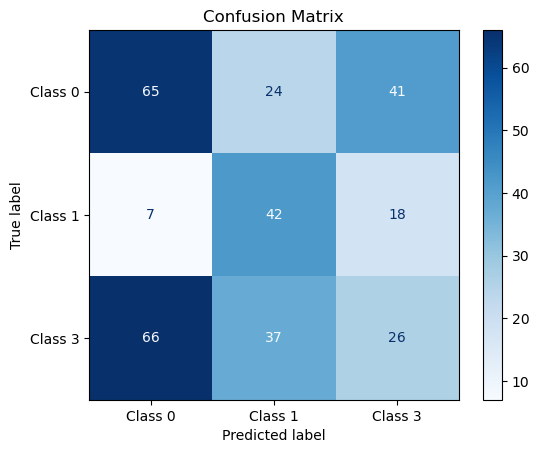

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.47      0.50      0.49       130
     Class 1       0.41      0.63      0.49        67
     Class 3       0.31      0.20      0.24       129

    accuracy                           0.41       326
   macro avg       0.39      0.44      0.41       326
weighted avg       0.39      0.41      0.39       326



In [21]:
# Confusion Matrix
# change "Class 0", "Class 1"
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1", "Class 3"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix")
plt.grid(False)
plt.show()

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Class 0", "Class 1", "Class 3"]))

# Kenneth's Section

## Setting Up Process

Read CSV

In [2]:
calc_test = pd.read_csv('data/csv/calc_case_description_test_set.csv')
calc_train = pd.read_csv('data/csv/calc_case_description_train_set.csv')
mass_test = pd.read_csv('data/csv/mass_case_description_test_set.csv')
mass_train = pd.read_csv('data/csv/mass_case_description_train_set.csv')

Choosing Features: (FEATURES CAN BE ADJUSTED)

In [15]:
features = ['breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'subtlety']

X_train = calc_train[features]          #Data Frame

y_train = calc_train['pathology']       #Series

X_test = calc_test[features]

y_test = calc_test['pathology']

#Combining data together but not needed
X = pd.concat([X_train, X_test])
y = (pd.concat([y_train, y_test])).to_frame()     #Concatenated series turns into Data Frame

Preprocessing (Converting categorical to encoded integers)   & Scaling


In [19]:
#Encode categorical Data into encoded integers
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded = enc.fit_transform(X_train)
X_test_encoded = enc.transform(X_test)

#Scale using StandardScaler()
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

### Training   & Prediction

In [157]:
#Trying Custom Weights      Maybe try to find optimal weight for Benign so that Brier score is minimize dbut also False negatives are reduced
custom_weight = {                       #Dictionary
    'BENIGN': 0.7,
    'BENIGN_WITHOUT_CALLBACK': 1.0,
    'MALIGNANT': 1.0
}

#Training and prediction
clf = LogisticRegression(max_iter=10000, class_weight= custom_weight, tol=0.00001, C=1, random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred = clf.predict(X_test_scaled)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred)}")

Test Accuracy: 0.7331288343558282


### Evaluation (Confusion Matrix and Brier Score)

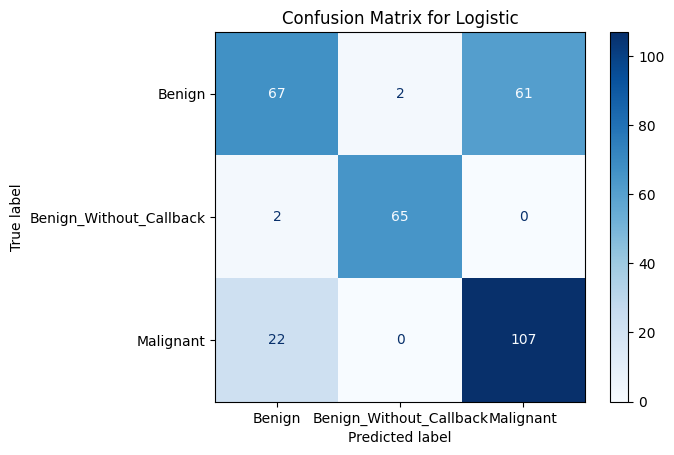

Classification Report:
                         precision    recall  f1-score   support

                 Benign       0.74      0.52      0.61       130
Benign_Without_Callback       0.97      0.97      0.97        67
              Malignant       0.64      0.83      0.72       129

               accuracy                           0.73       326
              macro avg       0.78      0.77      0.77       326
           weighted avg       0.75      0.73      0.73       326

Brier Score: 0.3192560013163171


In [158]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign',
                                                                   'Benign_Without_Callback',
                                                                   'Malignant'])

disp.plot(cmap='Blues')
plt.title("Confusion Matrix for Logistic")
plt.grid(False)
plt.show()

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign',
                                                          'Benign_Without_Callback',
                                                          'Malignant']))


#Brier Score
from sklearn.metrics import brier_score_loss

y_proba = clf.predict_proba(X_test_scaled)
brier_score = brier_score_loss(y_test, y_proba)
print(f"Brier Score: {brier_score}")


## Putting it All Together

### Function

In [ ]:
def run_Logistic(train_file, test_file, custom_weight, plot_cm=False, show_brier=False):
    train_data = pd.read_csv(f"{train_file}")
    test_data = pd.read_csv(f"{test_file}")
    
    #Features are different if calc or mass
    if train_file.startswith("data/csv/calc") and test_file.startswith("data/csv/calc"):
        features = ['breast density', 'left or right breast', 'image view',                     # Features is different with "breast_density" or
            'abnormality id', 'abnormality type', 'calc type', 'calc distribution',             # "breast density"
            'assessment', 'subtlety']
        
    elif train_file.startswith("data/csv/mass") and test_file.startswith("data/csv/mass"):
        features = ['breast_density', 'left or right breast', 'image view',
            'abnormality id', 'abnormality type', 'mass shape', 'mass margins',             
            'assessment', 'subtlety']

    else:
        print("Files don't match")
        return

    #Getting training and test data columns
    X_train = train_data[features]                   #Data Frame

    y_train = train_data["pathology"]                #Panda Series

    X_test = test_data[features]
    y_test = test_data['pathology']


    #Preprocessing

    #Encoding
    enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    X_train_encoded = enc.fit_transform(X_train)
    X_test_encoded = enc.transform(X_test)

    #Scaling
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_encoded)
    X_test_scaled = scaler.transform(X_test_encoded)


    #Actually training and predicting
    clf = LogisticRegression(max_iter=10000, class_weight=custom_weight, tol=0.00001, C=1, random_state=42)
    clf.fit(X_train_scaled, y_train)

    y_pred = clf.predict(X_test_scaled)
    print(f"Accuracy: {accuracy_score(y_test, y_pred)}")


    #Confusion Matrix
    if plot_cm == True:
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign',
                                                                           'Benign_Without_Callback',
                                                                           'Malignant'
                                                                           ])
        disp.plot(cmap="Blues")
        plt.title("Confusion Matrix for Logistic")
        plt.grid(False)
        plt.show()

        #Detailed Classification Report
        print("Classification Report")
        print(classification_report(y_test, y_pred, target_names=['Benign',
                                                                  'Benign_Without_Callback',
                                                                  'Malignant'
                                                                  ]))


    if show_brier == True:
        y_proba = clf.predict_proba(X_test_scaled)
        brier_score = brier_score_loss(y_test, y_proba)
        print("Brier Score: ", brier_score)



### Main

Accuracy: 0.7576687116564417


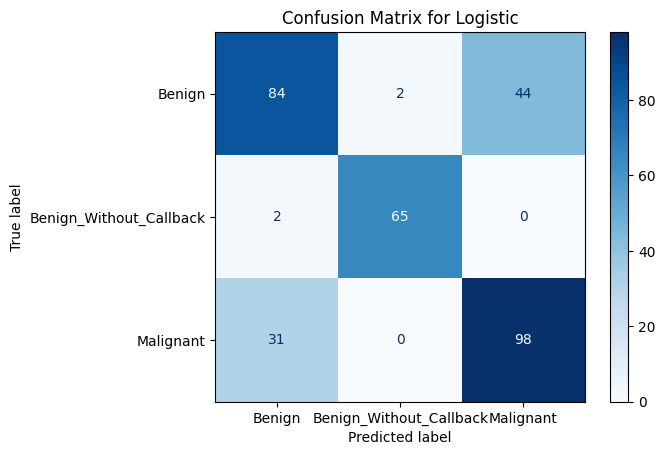

Classification Report
                         precision    recall  f1-score   support

                 Benign       0.72      0.65      0.68       130
Benign_Without_Callback       0.97      0.97      0.97        67
              Malignant       0.69      0.76      0.72       129

               accuracy                           0.76       326
              macro avg       0.79      0.79      0.79       326
           weighted avg       0.76      0.76      0.76       326

Brier Score:  0.31160109538050196
Accuracy: 0.7222222222222222


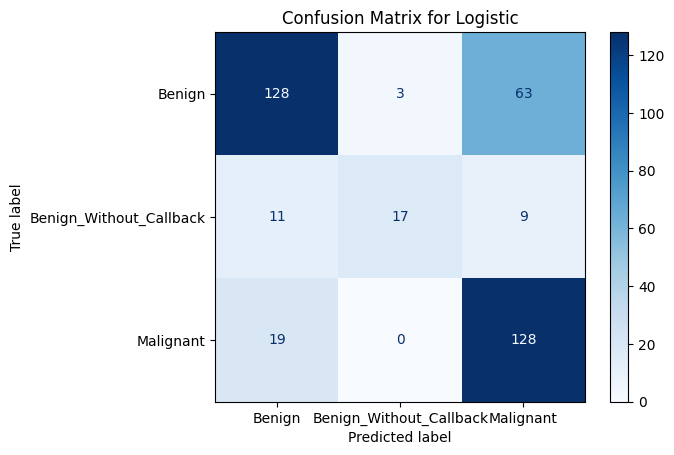

Classification Report
                         precision    recall  f1-score   support

                 Benign       0.81      0.66      0.73       194
Benign_Without_Callback       0.85      0.46      0.60        37
              Malignant       0.64      0.87      0.74       147

               accuracy                           0.72       378
              macro avg       0.77      0.66      0.69       378
           weighted avg       0.75      0.72      0.72       378

Brier Score:  0.37875105239845863


In [159]:
from sklearn.metrics import brier_score_loss

custom_weight = {                       #Dictionary         Maybe add custom weight for knn if that's possible?
    'BENIGN': 0.8,
    'BENIGN_WITHOUT_CALLBACK': 1.0,                         #Maybe adjust solver? Or look at other modifiable parameters
    'MALIGNANT': 1.0
    }

run_Logistic('data/csv/calc_case_description_train_set.csv', 
             'data/csv/calc_case_description_test_set.csv', 
             custom_weight,
             plot_cm=True, 
             show_brier=True)

run_Logistic('data/csv/mass_case_description_train_set.csv', 
             'data/csv/mass_case_description_test_set.csv', 
             custom_weight,
             plot_cm=True, 
             show_brier=True)

# Alyssa's Section